# 0.1 Data pipeline: GRAZPEDWRI-DX

`data/external/14825193.zip` → `data/interim/grazpedwri/` → `data/processed/`

The only manual step is downloading `14825193.zip` into `data/external/` (see `data/README.md`).
Each step skips work that is already done. Delete a step's output to redo it.

| Output | Contents |
|---|---|
| `processed/graz.csv` | One row per image: split, label, cast, follow-up, clean, metadata |
| `processed/graz_256x512_u8.npy` | Images, uint8, shape (20327, 512, 256), same row order as `graz.csv` |
| `processed/graz_boxes.csv` | YOLO boxes in 256x512 pixel coordinates |
| `interim/grazpedwri/` | Cleaned full-size 8-bit PNGs, their boxes and rotation angles |

In [1]:
import zipfile

import cv2
from joblib import Parallel, delayed
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.sparse import coo_matrix
from scipy.sparse.linalg import spsolve
from tqdm import tqdm

from snap.config import EXTERNAL_DATA_DIR, INTERIM_DATA_DIR, PROCESSED_DATA_DIR

SEED = 42
W, H = 256, 512
ZIP = EXTERNAL_DATA_DIR / "14825193.zip"
RAW = EXTERNAL_DATA_DIR / "grazpedwri"
CLEAN = INTERIM_DATA_DIR / "grazpedwri"
CLASSES = ["boneanomaly", "bonelesion", "foreignbody", "fracture", "metal",
           "periostealreaction", "pronatorsign", "softtissue", "text"]  # yolov5/meta.yaml
FRACTURE, TEXT = 3, 8

2026-11-11 13:17:14.226 | INFO     | snap.config:<module>:11 - PROJ_ROOT path is: E:\CCNY\CSC I1910\Project\wrist-fracture-detection


## 1. Extract

The bundle stores its inner zips uncompressed, so they are read in place without being written to disk.
A file is skipped if it already exists with the right size.

In [ ]:
def todo(z, dest):
    return [m for m in z.infolist() if not m.is_dir()
            and not ((dest / m.filename).exists() and (dest / m.filename).stat().st_size == m.file_size)]


with zipfile.ZipFile(ZIP) as outer:
    outer.extractall(RAW, [m for m in todo(outer, RAW)
                     if not m.filename.endswith(".zip")])
    for name in [n for n in outer.namelist() if n.endswith(".zip")]:
        inner = zipfile.ZipFile(outer.open(name))
        dest = RAW / "images" if name.startswith("images") else RAW
        missing = todo(inner, dest)
        print(f"{name}: extracting {len(missing)} of {len(inner.infolist())} files")
        inner.extractall(dest, missing)

assert len(list((RAW / "images").glob("*.png"))) == 20327

folder_structure.zip: extracting 0 of 60995 files


images_part1.zip: extracting 0 of 5031 files


images_part2.zip: extracting 0 of 5143 files


images_part3.zip: extracting 0 of 4842 files


images_part4.zip: extracting 0 of 5311 files


## 2. Labels and split

- `label`: `fracture_visible == 1`. Empty means no fracture.
- `follow_up`: `initial_exam` is empty.
- `clean`: first visit and no cast.
- Split 70/15/15 by `patient_id` with seed 42, so no child is in two splits.

In [ ]:
raw = pd.read_csv(RAW / "dataset.csv")
df = raw[["filestem", "patient_id", "age",
          "gender", "laterality", "projection"]].copy()
df["label"] = (raw["fracture_visible"] == 1).astype(int)
df["cast"] = (raw["cast"] == 1).astype(int)
df["follow_up"] = raw["initial_exam"].isna().astype(int)
df["clean"] = ((df["follow_up"] == 0) & (df["cast"] == 0)).astype(int)
df["metal"] = (raw["metal"] == 1).astype(int)
df["diagnosis_uncertain"] = (raw["diagnosis_uncertain"] == 1).astype(int)

kids = np.random.default_rng(SEED).permutation(df["patient_id"].unique())
n = len(kids)
df["split"] = df["patient_id"].map(
    {k: "train" if i < 0.7 * n else "val" if i < 0.85 * n else "test" for i, k in enumerate(kids)})

assert df["patient_id"].nunique() == 6091
assert df.groupby("patient_id")["split"].nunique().max() == 1
assert df["split"].value_counts().to_dict(
) == {"train": 14182, "val": 3202, "test": 2943}

PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)
df.to_csv(PROCESSED_DATA_DIR / "graz.csv", index=False)
df.groupby("split", sort=False).agg(images=("label", "size"), kids=("patient_id", "nunique"),
                                    fracture=("label", "mean"), cast=("cast", "mean"),
                                    clean=("clean", "sum")).round(3)

,images,kids,fracture,cast,clean
split,,,,,
val,3202,914,0.690,0.305,1633
train,14182,4264,0.666,0.281,7589
test,2943,913,0.645,0.278,1637


## 3. Clean images

For each image, at full size:

1. Window to the 1st–99th percentile of the X-ray field and convert to 8-bit. Marker pixels are left out of the percentiles.
2. Remove the L/R markers. Each YOLO `text` box covers only the letter, so it is padded by its own size to cover the marker plate, but never over a fracture box. Each patch is filled by straight-line interpolation across it, in whichever of 12 directions the two sides match best. That carries the arm edge and the dark border straight through. If no direction matches well (usually a marker at the image edge), the patch gets a smooth harmonic fill from its boundary instead. Noise matched to the image is added. OpenCV inpainting left diamond-shaped artifacts, and a plain blur left a visible grey square.
3. Rotate the X-ray field upright and crop away the black padding. This uses the smallest rotation that squares the field and skips tilts under 1°. Above 30° of tilt, it picks the rotation that leaves the field taller than wide. Landscape images with a small tilt stay landscape, since a 90° turn can put the hand at either end.
4. Apply the same rotation and crop to every YOLO box.

Output: `interim/grazpedwri/images/*.png`, `boxes.csv` (cleaned-image pixels) and `angles.csv`.

In [ ]:
# mean mismatch (of 255) between the two sides above which straight interpolation looks wrong
MAX_GAP = 35


def across(v, ok):
    """Interpolate down each column between the nearest ok pixels above and below; also return |above - below|."""
    r = np.arange(len(v))[:, None].repeat(v.shape[1], 1)
    up = np.maximum.accumulate(np.where(ok, r, -1), 0)
    dn = np.minimum.accumulate(np.where(ok, r, len(v))[::-1], 0)[::-1]
    c = np.arange(v.shape[1])
    a = np.where(up >= 0, v[up.clip(0), c], np.nan)
    b = np.where(dn < len(v), v[dn.clip(max=len(v) - 1), c], np.nan)
    return a + (b - a) * (r - up) / np.maximum(dn - up, 1), np.abs(b - a)


def harmonic(v, m):
    """Solve Laplace's equation inside m with the pixels around it as boundary values."""
    h, w = m.shape
    idx = np.full((h, w), -1)
    idx[m] = np.arange(m.sum())
    ys, xs = np.nonzero(m)
    rows, cols, rhs, deg = [], [], np.zeros(len(ys)), np.zeros(len(ys))
    for dy, dx in ((1, 0), (-1, 0), (0, 1), (0, -1)):
        ny, nx = ys + dy, xs + dx
        inside = (ny >= 0) & (ny < h) & (nx >= 0) & (nx < w)
        deg += inside
        ny, nx, i = ny[inside], nx[inside], np.nonzero(inside)[0]
        j = idx[ny, nx]
        rows.append(i[j >= 0])
        cols.append(j[j >= 0])
        np.add.at(rhs, i[j < 0], v[ny[j < 0], nx[j < 0]])
    n, r, c = len(ys), np.concatenate(rows), np.concatenate(cols)
    A = coo_matrix((np.r_[-np.ones(len(r)), deg],
                   (np.r_[r, np.arange(n)], np.r_[c, np.arange(n)])), (n, n))
    out = v.copy()
    out[m] = spsolve(A.tocsr(), rhs)
    return out


def fill(img, mask, field):
    ys, xs = np.nonzero(mask)
    cy, cx = (ys.min() + ys.max()) / 2, (xs.min() + xs.max()) / 2
    # room to rotate the patch inside the window
    r = int(np.hypot(np.ptp(ys), np.ptp(xs)) / 2) + 16
    win = np.s_[int(max(cy - r, 0)):int(cy + r) + 1,
                int(max(cx - r, 0)):int(cx + r) + 1]
    im, m = img[win], mask[win].astype(np.uint8)
    smooth = cv2.GaussianBlur(im, (0, 0), 3)
    size, c0 = im.shape[::-1], (cx - win[1].start, cy - win[0].start)
    best_gap, out = np.inf, None
    for ang in range(0, 180, 15):
        R = cv2.getRotationMatrix2D(c0, ang, 1)
        mr = cv2.warpAffine(m, R, size, flags=cv2.INTER_NEAREST)
        ok = cv2.warpAffine(np.ones_like(m), R, size,
                            flags=cv2.INTER_NEAREST) & (1 - mr)
        v, gap = across(cv2.warpAffine(smooth, R, size), ok > 0)
        # a side outside the image counts as the worst match
        gap = np.nan_to_num(gap[mr > 0], nan=255).mean()
        if gap < best_gap:
            best_gap, out = gap, cv2.warpAffine(np.nan_to_num(v).astype(
                np.float32), R, size, flags=cv2.INTER_LINEAR | cv2.WARP_INVERSE_MAP)
    if best_gap > MAX_GAP:
        out = harmonic(smooth, m > 0).astype(np.float32)
    detail = (im - smooth)[(m == 0) & field[win]]
    noise = 1.4826 * np.median(np.abs(detail)) if detail.size else 0
    out += np.random.default_rng(SEED).normal(0,
                                              noise, out.shape).astype(np.float32)
    # soften the patch edge
    alpha = cv2.GaussianBlur(m.astype(np.float32), (0, 0), 2)
    img[win] = im * (1 - alpha) + out * alpha
    return img


def clean(stem):
    a = cv2.imread(str(RAW / "images" / f"{stem}.png"), cv2.IMREAD_UNCHANGED)
    h, w = a.shape
    yolo = np.array((RAW / "yolov5" / "labels" /
                    f"{stem}.txt").read_text().split(), float).reshape(-1, 5)
    cls, cx, cy, bw, bh = yolo[:, 0].astype(
        int), yolo[:, 1] * w, yolo[:, 2] * h, yolo[:, 3] * w, yolo[:, 4] * h
    xy = np.stack([cx - bw / 2, cy - bh / 2, cx + bw / 2, cy + bh / 2], 1)

    mark = np.zeros((h, w), bool)
    for x0, y0, x1, y1 in xy[cls == TEXT]:
        p = max(x1 - x0, y1 - y0)
        mark[int(max(y0 - p, 0)):int(y1 + p) + 1,
             int(max(x0 - p, 0)):int(x1 + p) + 1] = True
    for x0, y0, x1, y1 in xy[cls == FRACTURE]:
        mark[int(max(y0, 0)):int(y1) + 1, int(max(x0, 0)):int(x1) + 1] = False
    lo, hi = np.percentile(a[(a > 0) & ~mark], [1, 99])
    img = np.clip((a - lo) / max(hi - lo, 1), 0, 1).astype(np.float32) * 255
    n, lab = cv2.connectedComponents(mark.astype(np.uint8))
    for i in range(1, n):  # one patch per marker, so far-apart markers don't share a window
        img = fill(img, lab == i, a > 0)
    img = img.clip(0, 255).round().astype(np.uint8)

    contours = cv2.findContours((a > 0).astype(
        np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[0]
    corners = cv2.boxPoints(cv2.minAreaRect(
        max(contours, key=cv2.contourArea)))
    edge = corners[1] - corners[0]
    angle = (np.degrees(np.arctan2(edge[1], edge[0])) + 45) % 90 - 45
    if abs(angle) > 30:  # near 45° both ways square the field; take the one that leaves it taller than wide
        dx, dy = np.ptp(
            corners @ cv2.getRotationMatrix2D((0, 0), angle, 1)[:, :2].T, 0)
        angle -= 90 * np.sign(angle) if dx > dy else 0
    angle = 0.0 if abs(angle) < 1 else angle
    M = cv2.getRotationMatrix2D((w / 2, h / 2), angle, 1)
    q = corners @ M[:, :2].T + M[:, 2]
    x0, y0 = np.floor(q.min(0))
    M[:, 2] -= (x0, y0)
    ow, oh = int(np.ceil(q[:, 0].max()) - x0), int(np.ceil(q[:, 1].max()) - y0)
    assert cv2.imwrite(
        str(CLEAN / "images" / f"{stem}.png"), cv2.warpAffine(img, M, (ow, oh)))

    pts = np.stack([xy[:, [0, 1]], xy[:, [2, 1]], xy[:, [2, 3]],
                   xy[:, [0, 3]]], 1) @ M[:, :2].T + M[:, 2]
    boxes = np.concatenate([pts.min(1), pts.max(1)],
                           1).clip(0, [ow, oh, ow, oh])
    return angle, np.column_stack([cls, boxes])


if not (CLEAN / "boxes.csv").exists():
    (CLEAN / "images").mkdir(parents=True, exist_ok=True)
    stems = df["filestem"].tolist()
    res = list(tqdm(Parallel(n_jobs=-1, max_nbytes=None, return_as="generator")
               (delayed(clean)(s) for s in stems), total=len(stems), mininterval=5))
    pd.DataFrame({"filestem": stems, "angle": [r[0] for r in res]}).to_csv(
        CLEAN / "angles.csv", index=False)
    pd.concat([pd.DataFrame(r[1], columns=["cls", "x0", "y0", "x1", "y1"]).assign(filestem=s)
               for s, r in zip(stems, res)]).to_csv(CLEAN / "boxes.csv", index=False)

angles = pd.read_csv(CLEAN / "angles.csv")
print(
    f"rotated: {(angles['angle'] != 0).mean():.1%}, max {angles['angle'].abs().max():.1f} deg")


  0%|          | 0/20327 [00:00<?, ?it/s]


  0%|          | 65/20327 [00:05<27:13, 12.41it/s]


  2%|▏         | 449/20327 [00:10<07:02, 47.03it/s]


  4%|▍         | 785/20327 [00:15<05:51, 55.66it/s]


  5%|▌         | 1064/20327 [00:20<05:51, 54.78it/s]


  7%|▋         | 1365/20327 [00:26<05:37, 56.19it/s]

... (64 outputs left out)


 98%|█████████▊| 20016/20327 [06:32<00:06, 51.29it/s]


100%|█████████▉| 20274/20327 [06:40<00:01, 45.07it/s]


100%|██████████| 20327/20327 [06:40<00:00, 50.79it/s]

rotated: 56.4%, max 57.4 deg


## 4. Resize and pack

Fit each cleaned image into 256x512 with its aspect ratio kept, centre it, and pad with black. Boxes get the same scale and offset.

In [ ]:
def fit(stem):
    im = cv2.imread(
        str(CLEAN / "images" / f"{stem}.png"), cv2.IMREAD_GRAYSCALE)
    k = min(W / im.shape[1], H / im.shape[0])
    return cv2.resize(im, (round(im.shape[1] * k), round(im.shape[0] * k)), interpolation=cv2.INTER_AREA), k


out = PROCESSED_DATA_DIR / "graz_256x512_u8.npy"
if not out.exists():
    tmp = out.with_suffix(".tmp.npy")
    X = np.lib.format.open_memmap(
        tmp, mode="w+", dtype=np.uint8, shape=(len(df), H, W))
    place = []
    jobs = Parallel(n_jobs=-1, max_nbytes=None,
                    return_as="generator")(delayed(fit)(s) for s in df["filestem"])
    for i, (im, k) in enumerate(tqdm(jobs, total=len(df), mininterval=5)):
        nh, nw = im.shape
        x, y = (W - nw) // 2, (H - nh) // 2
        X[i, y:y + nh, x:x + nw] = im
        place.append((df.at[i, "filestem"], k, x, y))
    X.flush()
    del X

    b = pd.read_csv(CLEAN / "boxes.csv").merge(pd.DataFrame(place,
                                                            columns=["filestem", "k", "dx", "dy"]))
    for c, d in [("x0", "dx"), ("x1", "dx"), ("y0", "dy"), ("y1", "dy")]:
        b[c] = (b[c] * b["k"] + b[d]).round(1)
    b["cls"] = b["cls"].astype(int)
    b["name"] = b["cls"].map(dict(enumerate(CLASSES)))
    b[["filestem", "cls", "name", "x0", "y0", "x1", "y1"]].to_csv(
        PROCESSED_DATA_DIR / "graz_boxes.csv", index=False)
    tmp.rename(out)


  0%|          | 0/20327 [00:00<?, ?it/s]


 28%|██▊       | 5781/20327 [00:05<00:12, 1153.41it/s]


 57%|█████▋    | 11549/20327 [00:12<00:09, 884.75it/s]


 81%|████████  | 16405/20327 [00:17<00:04, 914.82it/s]


100%|██████████| 20327/20327 [00:21<00:00, 939.31it/s]

## 5. Checks

In [ ]:
X = np.load(out, mmap_mode="r")
boxes = pd.read_csv(PROCESSED_DATA_DIR / "graz_boxes.csv")
frac = boxes[boxes["cls"] == FRACTURE]

assert X.shape == (len(df), H, W)
assert (X.reshape(len(X), -1).max(1) > 0).all(), "empty image"
assert ((frac["x1"] > frac["x0"]) & (frac["y1"] > frac["y0"])
        ).all(), "fracture box cropped away"
assert frac["x0"].min() >= 0 and frac["x1"].max(
) <= W and frac["y0"].min() >= 0 and frac["y1"].max() <= H
print(f"{len(frac)} fracture boxes on {frac['filestem'].nunique()} images")

18090 fracture boxes on 13550 images


Raw (top) vs processed (bottom), fracture boxes in red. The first three are the most rotated images, the rest are random.

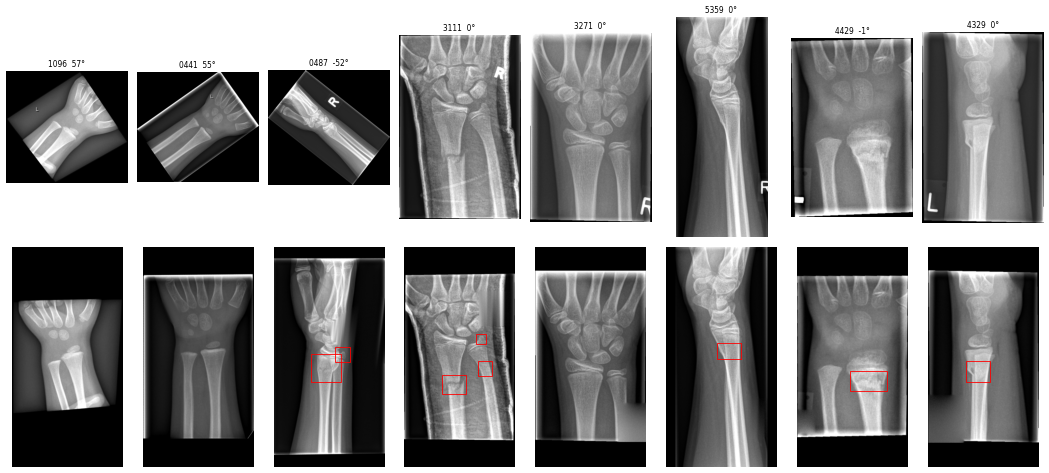

In [ ]:
pick = angles["angle"].abs().nlargest(3).index.tolist() + \
    df.sample(5, random_state=SEED).index.tolist()
fig, ax = plt.subplots(2, len(pick), figsize=(2.2 * len(pick), 8), dpi=60)
for j, i in enumerate(pick):
    stem = df.at[i, "filestem"]
    a = cv2.imread(str(RAW / "images" / f"{stem}.png"), cv2.IMREAD_UNCHANGED)
    ax[0, j].imshow(a, cmap="gray", vmin=np.percentile(
        a, 1), vmax=np.percentile(a, 99))
    ax[0, j].set_title(f"{stem[:4]}  {angles.at[i, 'angle']:.0f}°", fontsize=9)
    ax[1, j].imshow(X[i], cmap="gray")
    for r in frac[frac["filestem"] == stem].itertuples():
        ax[1, j].add_patch(plt.Rectangle(
            (r.x0, r.y0), r.x1 - r.x0, r.y1 - r.y0, fill=False, ec="r"))
    ax[0, j].axis("off")
    ax[1, j].axis("off")
fig.tight_layout()

## Loading in later notebooks

```python
X = np.load(PROCESSED_DATA_DIR / "graz_256x512_u8.npy", mmap_mode="r")  # (20327, 512, 256) uint8
df = pd.read_csv(PROCESSED_DATA_DIR / "graz.csv")  # same row order as X
train = df["split"] == "train"
```